# 18 从会训练模型，到做一项能解释的小研究

## 1 曲线贴住了样本，往外延长会怎样

一个网络可以把训练点拟合得很好。现在将横轴继续向右延伸：它会顺着真实曲线走，还是沿着自己的方向离开？这个小实验会把训练、模型选择与外推放到同一张图里。

真实规律取 $y=\sin(3x)$。网络只见到 [-1,1] 内的带噪声观测，我们却知道 [1,2] 内的真实曲线，因此可以检查它向未见区域延伸时的表现。下面的浅色区域就是那段将来才交给模型的输入。

我们会训练宽度为4和16的网络，用训练区间内另一组位置比较它们，再查看选定宽度在区间内外各自的误差。验证与测试用无噪声规律，衡量的是模型恢复这条曲线的程度。

In [1]:
from support import ROOT, check, show, style

In [2]:
import json
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
torch.set_num_threads(1)
style()

In [3]:
data_rng=np.random.default_rng(12)
x_train=np.sort(data_rng.uniform(-1,1,60)).astype('float32')[:,None]
y_train=np.sin(3*x_train)+data_rng.normal(0,.05,x_train.shape).astype('float32')
x_val=np.linspace(-.98,.98,41,dtype='float32')[:,None]
x_test=np.linspace(-.99,.99,80,dtype='float32')[:,None]
x_out=np.linspace(1.02,2,80,dtype='float32')[:,None]

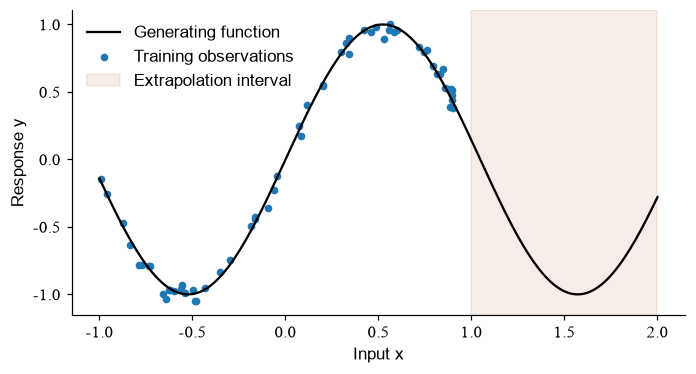

In [4]:
fig,ax=plt.subplots(figsize=(7.2,3.6))
axis=np.linspace(-1,2,200)
ax.plot(axis,np.sin(3*axis),color='black',label='Generating function')
ax.scatter(x_train,y_train,s=16,label='Training observations')
ax.axvspan(1,2,color='#B66A47',alpha=.12,label='Extrapolation interval')
ax.set(xlabel='Input x',ylabel='Response y');ax.legend(frameon=False)
show(fig)

### 练习 r01：计算一个集合的误差

真实值 `[1,2]`，预测 `[1.5,1.5]`，算均方误差。

In [5]:
ex_r01_mse=None

In [6]:
# 填写上一格后，运行检查。
check('MSE',ex_r01_mse,.25)

待填写：MSE


<details>
<summary>提示</summary>

先逐项相减、平方，再对两个样本平均。

</details>

<details>
<summary>参考答案</summary>

```python
ex_r01_mse=np.mean((np.array([1.5,1.5])-np.array([1.,2.]))**2)
```

</details>

## 2 给同一个任务两种容量

宽度4和16意味着隐藏层有不同数量的可调曲线成分。更宽的网络可以表示更多变化，但最终学到的曲线还受初始权重与优化过程影响。每种宽度从三个不同的初始化开始，便能看见一次运行以外的变化。

两种网络使用同一份数据、Tanh 激活和200次更新。宽模型每步处理的参数更多，输出中也会列出参数量；这次比较的是相同更新次数下的结果。

In [7]:
train_x=torch.from_numpy(x_train);train_y=torch.from_numpy(y_train)
validation_x=torch.from_numpy(x_val)
configurations=[dict(width=4),dict(width=16)]
seeds=[0,1,2]
print('训练输入、目标：',train_x.shape,train_y.shape)

训练输入、目标： torch.Size([60, 1]) torch.Size([60, 1])


把一次运行写成透明的小函数：新建模型、更新200次、返回模型与训练曲线。评价函数只接收已有模型，不更新参数。

In [8]:
def fit_once(width,seed):
    torch.manual_seed(seed)
    model=nn.Sequential(nn.Linear(1,width),nn.Tanh(),nn.Linear(width,1))
    optimizer=torch.optim.Adam(model.parameters(),lr=.03)
    losses=[]
    for step in range(200):
        loss=((model(train_x)-train_y)**2).mean()
        optimizer.zero_grad(set_to_none=True)
        loss.backward();optimizer.step()
        losses.append(loss.item())
    return model,losses
@torch.no_grad()
def error(model,x):
    model.eval()
    target=torch.sin(3*torch.from_numpy(x))
    return ((model(torch.from_numpy(x))-target)**2).mean().item()

### 练习 r02：每个配置应该跑几次

列出 width 为 4、16 且 seed 为 0、1、2 的全部组合。

In [9]:
ex_r02_pairs=None

In [10]:
# 填写上一格后，运行检查。
check('实验组合',ex_r02_pairs,[[4,0],[4,1],[4,2],[16,0],[16,1],[16,2]])

待填写：实验组合


<details>
<summary>提示</summary>

外层循环配置，内层循环种子。

</details>

<details>
<summary>参考答案</summary>

```python
ex_r02_pairs=[(width,seed) for width in [4,16] for seed in [0,1,2]]
```

</details>

In [11]:
records=[];trained={}
for cfg in configurations:
    for seed in seeds:
        model,losses=fit_once(cfg['width'],seed)
        validation=error(model,x_val)
        key=(cfg['width'],seed);trained[key]=model
        records.append(dict(width=cfg['width'],seed=seed,val_mse=validation,
                            parameters=sum(p.numel() for p in model.parameters()),
                            first_loss=losses[0],last_loss=losses[-1]))
print(*records,sep='\n')

{'width': 4, 'seed': 0, 'val_mse': 0.030667360872030258, 'parameters': 13, 'first_loss': 0.6485849022865295, 'last_loss': 0.026825224980711937}
{'width': 4, 'seed': 1, 'val_mse': 0.013469438999891281, 'parameters': 13, 'first_loss': 0.5450887084007263, 'last_loss': 0.012676623649895191}
{'width': 4, 'seed': 2, 'val_mse': 0.02359282597899437, 'parameters': 13, 'first_loss': 0.5003204345703125, 'last_loss': 0.0212992113083601}
{'width': 16, 'seed': 0, 'val_mse': 0.006267359480261803, 'parameters': 49, 'first_loss': 0.459878534078598, 'last_loss': 0.006679994985461235}
{'width': 16, 'seed': 1, 'val_mse': 0.005858755204826593, 'parameters': 49, 'first_loss': 0.6231752634048462, 'last_loss': 0.006274534855037928}
{'width': 16, 'seed': 2, 'val_mse': 0.007822790183126926, 'parameters': 49, 'first_loss': 0.6146472692489624, 'last_loss': 0.00794218759983778}


## 3 从六次结果里选择一个宽度

现在每种宽度都有三份验证误差。它们来自同一组验证位置，差别在于初始权重。把每组的三个误差取平均，选均值较低的宽度；旁边的样本标准差描述这三次初始化带来的散布。

验证位置没有参与梯度更新，却参与了这次选择。稍后另外一组测试位置会评价已经选好的宽度，这样便能分开“据此作选择”和“查看选择后的结果”两个动作。

In [12]:
validation_means={}
for width in [4,16]:
    values=np.array([r['val_mse'] for r in records if r['width']==width])
    validation_means[width]=float(values.mean())
    print('width=',width,'values=',values,'mean=',values.mean(),'std=',values.std(ddof=1))
chosen_width=min(validation_means,key=validation_means.get)
print('验证集选定宽度：',chosen_width)

width= 4 values= [0.03066736 0.01346944 0.02359283] mean= 0.022576541950305302 std= 0.008643885359042853
width= 16 values= [0.00626736 0.00585876 0.00782279] mean= 0.0066496349560717745 std= 0.0010363200536277885
验证集选定宽度： 16


### 练习 r03：根据验证误差选模型

候选均值 `{4:0.04,16:0.02}`，返回选定宽度。

In [13]:
ex_r03_width=None

In [14]:
# 填写上一格后，运行检查。
check('选定配置',ex_r03_width,16)

待填写：选定配置


<details>
<summary>提示</summary>

比较字典的值，返回对应的键。

</details>

<details>
<summary>参考答案</summary>

```python
ex_r03_scores={4:.04,16:.02}
ex_r03_width=min(ex_r03_scores,key=ex_r03_scores.get)
```

</details>

## 4 配置确定后查看测试结果

对选定宽度的三个种子统一计算插值和外推误差。外推区域的输入分布已经改变；分别报告两个区域，才能看见模型在哪种问题上有效。

In [15]:
test_records=[]
for seed in seeds:
    model=trained[(chosen_width,seed)]
    test_records.append(dict(width=chosen_width,seed=seed,
                             interpolation_mse=error(model,x_test),extrapolation_mse=error(model,x_out)))
print(*test_records,sep='\n')

{'width': 16, 'seed': 0, 'interpolation_mse': 0.00622605811804533, 'extrapolation_mse': 0.2598254084587097}
{'width': 16, 'seed': 1, 'interpolation_mse': 0.0058254883624613285, 'extrapolation_mse': 0.21465477347373962}
{'width': 16, 'seed': 2, 'interpolation_mse': 0.007770150899887085, 'extrapolation_mse': 0.33288732171058655}


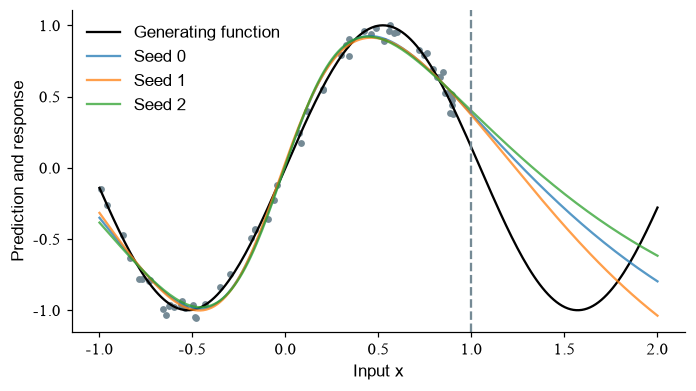

In [16]:
fig,ax=plt.subplots(figsize=(7.2,3.8))
ax.plot(axis,np.sin(3*axis),color='black',label='Generating function')
with torch.no_grad():
    for seed in seeds:
        prediction=trained[(chosen_width,seed)](torch.tensor(axis[:,None],dtype=torch.float32)).numpy()
        ax.plot(axis,prediction[:,0],label=f'Seed {seed}',alpha=.75)
ax.axvline(1,color='#758A95',ls='--');ax.scatter(x_train,y_train,s=12,color='#758A95')
ax.set(xlabel='Input x',ylabel='Prediction and response');ax.legend(frameon=False)
show(fig)

### 练习 r04：解释多次运行的散布

对 `[0.02,0.03,0.04]` 计算均值与样本标准差。

In [17]:
ex_r04_mean=None
ex_r04_std=None

In [18]:
# 填写上一格后，运行检查。
check('三次均值',ex_r04_mean,.03)
check('样本标准差',ex_r04_std,.01)

待填写：三次均值
待填写：样本标准差


<details>
<summary>提示</summary>

标准差使用 ddof=1。

</details>

<details>
<summary>参考答案</summary>

```python
ex_r04_mean=np.mean([.02,.03,.04])
ex_r04_std=np.std([.02,.03,.04],ddof=1)
```

</details>

## 5 把问题、实现与观察连起来

沿图检查三个种子在训练区间内是否接近；再看区间外是否分开。用实测误差回答当前问题。模型在训练数据上损失下降，说明优化确实找到了能拟合这些样本的参数；外推能力还取决于结构、数据覆盖与生成规律。

下一轮可以保持宽度不变，只把 Tanh 改为 ReLU；或者保持模型不变，只扩大训练区间。分别提出预期，再运行对照。

### 练习 r05：为一个测试样本标记区域

输入 `[0.2,0.8,1.4]`，以 x>1 标记外推区域。

In [19]:
ex_r05_out=None

In [20]:
# 填写上一格后，运行检查。
check('外推区域',ex_r05_out,[False,False,True])

待填写：外推区域


<details>
<summary>提示</summary>

逐元素比较会产生布尔数组。

</details>

<details>
<summary>参考答案</summary>

```python
ex_r05_out=np.array([.2,.8,1.4])>1
```

</details>

## 6 保存可重新解释的记录

记录包括生成规律、固定数据种子、候选配置、优化种子、更新次数、验证选择和测试结果。别人读到一个数字时，应能找到它对应的运行。

In [21]:
experiment=dict(problem='sin(3x), noisy training observations',data_seed=12,
                widths=[4,16],optimization_seeds=seeds,updates=200,
                chosen_width=chosen_width,validation=records,test=test_records)
destination=ROOT/'.build'/'artifacts';destination.mkdir(parents=True,exist_ok=True)
(destination/'research_experiment.json').write_text(json.dumps(experiment,indent=2),encoding='utf-8')
print('记录位置：',destination/'research_experiment.json')

记录位置： <课程目录>\.build\artifacts\research_experiment.json


### 练习 r06：写下下一轮的控制变量

将保持不变的量写进字典：width=16、seed=0、updates=200。

In [22]:
ex_r06_controls=None

In [23]:
# 填写上一格后，运行检查。
check('固定设置',ex_r06_controls,dict(width=16,seed=0,updates=200))

待填写：固定设置


<details>
<summary>提示</summary>

每个键记录一项设置。

</details>

<details>
<summary>参考答案</summary>

```python
ex_r06_controls=dict(width=16,seed=0,updates=200)
```

</details>

## 7 按研究对象选择下一步

| 对象 | 可以检验的结构假设 | 一个具体对照 |
| --- | --- | --- |
| 标定响应 | MLP 能表示非线性 | 与线性模型比较独立测量上的误差 |
| 图像/波形局部模式 | 卷积共享局部检测器 | 固定参数量，改变平移与位置 |
| 时序记忆 | 隐状态保留过去信息 | 改变依赖间隔并检查早期梯度 |
| 序列关系 | 注意力读取相关位置 | 对固定输入遮挡特定位置，测量损失变化 |
| 探测通道/图结构 | 邻接关系辅助信息聚合 | 与打乱边的图、无边 MLP 对照 |
| 不规则采样过程 | 连续时间状态使用实际 Δt | 固定观测值，改变采样间隔检验响应 |

论文阅读顺序：先写任务和实验对象，再找模型方程、训练目标、基线、数据划分与主要结果表。将其中一个结论缩小到自己能复现的小实验，检查它需要哪些条件。

## 8 把这些网络放回机器学习的版图

数字分类与字符生成看起来不同，却都要连接六件事：

| 环节 | 第09课的数字分类 | 第14课的下一字符预测 |
| --- | --- | --- |
| 任务 | 根据图像预测类别 | 根据前文预测后一个字符 |
| 数据表示 | 样本、通道、高、宽 | 样本、位置、嵌入特征 |
| 模型结构 | CNN 的局部连接与共享卷积核 | Transformer 的位置与因果注意力 |
| 训练信号 | 人给图像标出的数字 | 原文中本来就有的后一个字符 |
| 损失 | 正确类别的负对数概率 | 真实后续字符的负对数概率 |
| 参数更新 | 对损失反传，再更新权重 | 对损失反传，再更新权重 |
| 优化器 | Adam | AdamW |

第一种训练信号是**监督学习**中的人工标签。第二种从数据自身构造目标，称为**自监督学习**。同一种网络结构可以换任务，同一个任务也可以换结构；先写清输入、目标与评价量，再决定用哪种网络。

把模型记为 $f_\theta$，θ 是全部可训练参数。第 i 个样本为 $(x_i,y_i)$，共 N 个样本，单个样本的损失记为 ℓ。训练时计算的是有限样本上的平均：
$$\widehat R(\theta)=\frac1N\sum_{i=1}^N\ell(f_\theta(x_i),y_i).$$
其中 ℓ 可以是本课的平方误差，也可以是分类中的交叉熵。**优化**研究如何降低这个训练目标；**泛化**关心新样本上的损失。若新样本来自分布 p，其平均损失写成
$$R_p(\theta)=\mathbb E_{(x,y)\sim p}[\ell(f_\theta(x),y)].$$
期望符号表示按 p 的出现频率对所有可能样本求平均。实验里只能用有限的独立样本估计它。这里的插值与外推使用不同输入区域，因此对应不同的 p；训练损失相近的两个网络，在区域外可以产生很不一样的曲线。

**表示**关心模型能构成什么函数。卷积的局部连接、图网络的邻居聚合、LTC 的连续时间状态，都把某些关系提前写进结构；这种偏好称为归纳偏置。它是否适合任务，可以通过平移、打乱边、改变采样间隔等对照来检验。

读论文时，先把新方法放在这三处之一：它改变了表示、优化，还是训练信号与数据？再找出支持相应主张的对照实验。沿这条线阅读，网络名称就能和具体的问题、方程与证据对应起来。

## 带着问题读原文

[Neural Ordinary Differential Equations](https://arxiv.org/abs/1806.07366)

读从离散残差更新走到连续时间微分方程的定义。对照第09、17课：改变的是模型参数化、积分步长还是训练目标？分别设计只改变其中一项的实验。